# Monitoring — Dérive des données et des concepts

Un modèle classe des avis de patients sur des médicaments contre la douleur (*Pain* dans les données) : positifs (note 10) ou négatifs (note 1). En production, il reçoit des lots d'avis dont l'étiquette n'arrive que bien plus tard. Avec la bibliothèque Evidently, cette démonstration surveille trois situations :

1. deux bugs dans la chaîne de traitement des données ;
2. une dérive progressive des données, vers des avis d'un autre domaine ;
3. une dérive des concepts : les mêmes avis, dont le sens a changé.

In [1]:
# @title Mise en place de l'environnement
!pip install -q "evidently>=0.7,<0.8" "pandas<3"

import random
import warnings

import nltk
import pandas
import sklearn.feature_extraction.text
import sklearn.linear_model
import sklearn.model_selection
import sklearn.pipeline
from evidently import BinaryClassification, DataDefinition, Dataset, Report
from evidently.descriptors import (
  NonLetterCharacterPercentage,
  OOVWordsPercentage,
  SentenceCount,
  TextLength,
  WordCount,
)
from evidently.metrics import DriftedColumnsCount, ValueDrift
from evidently.presets import ClassificationPreset, DataDriftPreset
from evidently.tests import lt

warnings.filterwarnings("ignore")

for corpus in ["words", "wordnet", "omw-1.4"]:
  nltk.download(corpus, quiet=True)


def telecharge_avis_medicaments() -> tuple[pandas.DataFrame, pandas.DataFrame]:
  """Data source: https://archive.ics.uci.edu/ml/datasets/Drug+Review+Dataset+%28Drugs.com%29

  Citation:
    Felix Gräßer, Surya Kallumadi, Hagen Malberg, and Sebastian Zaunseder.
    2018.
    Aspect-Based Sentiment Analysis of Drug Reviews Applying Cross-Domain and Cross-Data Learning.
    In Proceedings of the 2018 International Conference on Digital Health (DH '18).
    ACM, New York, NY, USA, 121-125.
  """
  donnees_brutes = pandas.read_csv(
    "https://github.com/shuuchuu/datasets/raw/refs/heads/main/drug-reviews/drugsComTest_raw.tsv",
    sep="\t",
    index_col=0,
  )
  return donnees_brutes[["drugName", "condition", "review", "rating"]]


def filtre_avis_medicaments(df: pandas.DataFrame, condition: str) -> pandas.DataFrame:
  df = df.loc[
    (df["condition"] == condition) & (df["rating"].isin([1, 10])),
    ["review", "rating"],
  ]
  df["est_positif"] = df["rating"].apply(lambda x: 0 if x == 1 else 1)
  return df.drop(columns="rating")


def separe_avis_medicaments(
  df: pandas.DataFrame,
) -> tuple[pandas.DataFrame, pandas.DataFrame]:
  X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(
    df["review"], df["est_positif"], test_size=0.4, random_state=42, shuffle=True
  )

  reference = pandas.DataFrame({"review": X_train, "est_positif": y_train})
  validation = pandas.DataFrame({"review": X_test, "est_positif": y_test})
  return reference, validation


def exactitude(df: pandas.DataFrame) -> float:
  return (df["predictions"] == df["est_positif"]).mean()


balises_html_aleatoires = (
  "<body>",
  "</body>",
  "<html><body>",
  "</body></html>",
  "<h1>",
  "</h1>",
  '<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 0 0" width="0" height="0" focusable="false" role="none" style="visibility: hidden; position: absolute; left: -9999px; overflow: hidden;"><defs><filter id="wp-duotone-magenta-yellow"><feColorMatrix color-interpolation-filters="sRGB" type="matrix" values=" .299 .587 .114 0 0 .299 .587 .114 0 0 .299 .587 .114 0 0 .299 .587 .114 0 0 "></feColorMatrix><feComponentTransfer color-interpolation-filters="sRGB"><feFuncR type="table" tableValues="0.78039215686275 1"></feFuncR><feFuncG type="table" tableValues="0 0.94901960784314"></feFuncG><feFuncB type="table" tableValues="0.35294117647059 0.47058823529412"></feFuncB><feFuncA type="table" tableValues="1 1"></feFuncA></feComponentTransfer><feComposite in2="SourceGraphic" operator="in"></feComposite></filter></defs></svg>',
)


def injecte_balises_html_aleatoires(texte):
  nb_balises = 25
  for i in range(nb_balises):
    random.seed(i)
    position = random.choice(range(len(texte)))
    texte = texte[:position] + random.choice(balises_html_aleatoires) + texte[position:]

  return texte

## Le modèle surveillé

Le modèle est entraîné sur 60 % des avis sur la douleur. Les 40 % restants jouent les données de production : leurs étiquettes, connues ici, mesurent ce que le monitoring voit ou ne voit pas.

In [2]:
donnees_brutes = telecharge_avis_medicaments()
reference_df, actuel_df = separe_avis_medicaments(
  filtre_avis_medicaments(donnees_brutes, "Pain")
)

pipeline = sklearn.pipeline.Pipeline(
  [
    (
      "vectorization",
      sklearn.feature_extraction.text.TfidfVectorizer(
        sublinear_tf=True, max_df=0.5, stop_words="english"
      ),
    ),
    (
      "classification",
      sklearn.linear_model.SGDClassifier(
        alpha=0.0001,
        max_iter=50,
        penalty="l1",
        loss="modified_huber",
        random_state=42,
      ),
    ),
  ]
)
pipeline.fit(reference_df["review"].values, reference_df["est_positif"].values)
reference_df["predictions"] = pipeline.predict(reference_df["review"].values)
actuel_df["predictions"] = pipeline.predict(actuel_df["review"].values)

print(f"Avis d'entraînement : {len(reference_df)}, de validation : {len(actuel_df)}")
print(f"Exactitude sur la validation : {exactitude(actuel_df):.0%}")

Avis d'entraînement : 555, de validation : 371
Exactitude sur la validation : 84%


Sur des avis qu'il n'a pas vus, le modèle a raison 84 fois sur 100 : c'est la performance que le monitoring doit préserver.

## 1. Deux bugs dans la chaîne de traitement

Un lot de production arrive abîmé par deux bugs courants : le nettoyage des balises HTML ne se fait plus pour une partie des avis, et la récupération des données en ramène d'autres dans une autre langue (ici, leur traduction en français).

In [3]:
# La traduction automatique en français de chaque avis sur la douleur : la
# « langue différente » du bug de récupération des données
avis_traduits = pandas.read_csv(
  "https://github.com/shuuchuu/datasets/raw/refs/heads/main/drug-reviews/drugsComTest_pain_fr.tsv",
  sep="\t",
  index_col="id",
)["review"]

actuel_perturbe_df = actuel_df[["review", "est_positif"]].copy()
nb_perturbes = int(len(actuel_perturbe_df) * 0.5)
random.seed(42)
indices_perturbes = random.sample(list(actuel_perturbe_df.index), k=nb_perturbes)
avec_balises = indices_perturbes[: int(nb_perturbes / 10)]
traduits = indices_perturbes[int(nb_perturbes / 10) :]
actuel_perturbe_df.loc[avec_balises, "review"] = actuel_perturbe_df.loc[
  avec_balises, "review"
].apply(injecte_balises_html_aleatoires)
actuel_perturbe_df.loc[traduits, "review"] = avis_traduits.loc[traduits]
actuel_perturbe_df["predictions"] = pipeline.predict(
  actuel_perturbe_df["review"].values
)

print(f"Avis du lot : {len(actuel_perturbe_df)}")
print(f"Avec des balises HTML : {len(avec_balises)}, en français : {len(traduits)}")

Avis du lot : 371
Avec des balises HTML : 18, en français : 167


Rien n'arrête ce lot : le modèle le prédit comme les autres, et ses étiquettes n'arriveront que bien plus tard.

### Rapport de dérive des données

Evidently calcule des descripteurs de chaque avis (longueur, nombre de phrases et de mots, part de mots hors vocabulaire et de caractères qui ne sont pas des lettres), puis compare leur distribution, et celle des prédictions, entre le lot reçu et un lot propre.

In [4]:
descripteurs = [
  NonLetterCharacterPercentage("review", alias="non_letters"),
  OOVWordsPercentage("review", alias="oov"),
  SentenceCount("review", alias="sentence_count"),
  TextLength("review", alias="text_length"),
  WordCount("review", alias="word_count"),
]
colonnes_descripteurs = [
  "non_letters",
  "oov",
  "sentence_count",
  "text_length",
  "word_count",
]
definition_donnees = DataDefinition(
  text_columns=["review"],
  classification=[
    BinaryClassification(target="est_positif", prediction_labels="predictions")
  ],
)
reference, actuel, actuel_perturbe = (
  Dataset.from_pandas(df, data_definition=definition_donnees, descriptors=descripteurs)
  for df in (reference_df, actuel_df, actuel_perturbe_df)
)

# Les étiquettes (est_positif) ne servent pas : le rapport compare les prédictions
# et les descripteurs du texte du lot reçu à ceux d'un lot propre
rapport = Report([DataDriftPreset(columns=["predictions", *colonnes_descripteurs])])
instantane = rapport.run(current_data=actuel_perturbe, reference_data=actuel)
instantane

Quatre colonnes sur six dérivent : la part de mots hors vocabulaire, la longueur des avis, leur nombre de phrases et les prédictions, plus souvent négatives. Sans aucune étiquette, le lot est signalé le jour même.

### Inspection des avis suspects

Les descripteurs qui dérivent disent où regarder : les avis très longs, et ceux dont beaucoup de mots sont hors vocabulaire.

In [5]:
perturbe_df = actuel_perturbe.as_dataframe()
avis_longs = perturbe_df[perturbe_df["text_length"] > 1000]
avec_html = avis_longs["review"].str.contains("<body>|<h1>|<svg")
print(f"Avis de plus de 1 000 caractères : {len(avis_longs)}")
print(f"dont avec des balises HTML : {avec_html.sum()}")
perturbe_df.loc[perturbe_df["oov"] > 30, ["review", "oov"]].head()

Avis de plus de 1 000 caractères : 18
dont avec des balises HTML : 18


,review,oov
197586,"""Chaque fois que j'éprouve des douleurs dues à...",72.115385
43603,"""Je prends du dilaudid pour traiter de graves ...",60.839161
94484,"""Je prends ce médicament depuis 3 ans pour sou...",77.966102
43595,"""Pendant que j'étais aux urgences, le diagnost...",67.272727
189144,"""I have been on 4-5, 15 mg oxycodones a day fo...",54.858934


Les avis de plus de 1 000 caractères sont ceux qui portent des balises HTML, et les avis riches en mots hors vocabulaire (un dictionnaire anglais) sont en français, ou truffés de balises : les deux bugs sont identifiés.

### Ce que montrent les étiquettes

Une fois les étiquettes connues, la vérité terrain mesure le coût des bugs.

In [6]:
print(f"Exactitude sur le lot propre : {exactitude(actuel_df):.0%}")
print(f"Exactitude sur le lot reçu : {exactitude(actuel_perturbe_df):.0%}")

Exactitude sur le lot propre : 84%
Exactitude sur le lot reçu : 76%


Les bugs coûtent 8 points d'exactitude. Ce chiffre demandait la vérité terrain, qui arrive des jours ou des semaines après les prédictions : les descripteurs ont alerté bien avant.

## 2. Dérive progressive des données

En production, la population change rarement d'un coup. Des lots de 300 avis arrivent, où la part d'avis sur des médicaments contre la dépression (*Depression* dans les données) monte de 0 à 100 % : le modèle, entraîné sur la douleur, voit arriver un autre domaine.

Chaque lot passe deux tests de dérive, face aux données d'entraînement : moins de 30 % des colonnes surveillées (le texte, les prédictions, les descripteurs) en dérive, et un score de dérive du texte sous 0,6. Si l'un échoue, une alerte est levée.

In [7]:
nouveau_contenu_df = filtre_avis_medicaments(donnees_brutes, "Depression")
nouveau_contenu_df["predictions"] = pipeline.predict(
  nouveau_contenu_df["review"].values
)


def fabrique_lot(part_depression: float, taille: int = 300) -> Dataset:
  nb_depression = int(taille * part_depression)
  lot_df = pandas.concat(
    [
      actuel_df.sample(taille - nb_depression, random_state=42),
      nouveau_contenu_df.sample(nb_depression, random_state=42),
    ]
  )
  return Dataset.from_pandas(
    lot_df, data_definition=definition_donnees, descriptors=descripteurs
  )


# Les tests de dérive de chaque lot, face aux données d'entraînement : moins de
# 30 % des colonnes surveillées en dérive, et un score de dérive du texte sous 0,6
colonnes_surveillees = ["review", "predictions", *colonnes_descripteurs]
rapport_derive = Report(
  [
    DriftedColumnsCount(columns=colonnes_surveillees, share_tests=[lt(0.3)]),
    ValueDrift(column="review", tests=[lt(0.6)]),
  ]
)


def leve_alerte(instantane) -> bool:
  return any(test["status"] == "FAIL" for test in instantane.dict()["tests"])

### Tableau de bord des lots

Un tableau de bord suit ces indicateurs lot après lot, avec l'exactitude, qu'en production on ne connaîtrait que bien plus tard.

Alerte levée dès 20% d'avis Depression


,part_depression,colonnes_derivees,derive_avis,alerte,exactitude
0,0.0,0.142857,0.504998,False,0.840000
1,0.2,0.428571,0.496160,True,0.823333
2,0.4,0.571429,0.612435,True,0.803333
3,0.6,0.571429,0.660027,True,0.780000
4,0.8,0.714286,0.775949,True,0.740000
5,1.0,0.714286,0.913024,True,0.736667


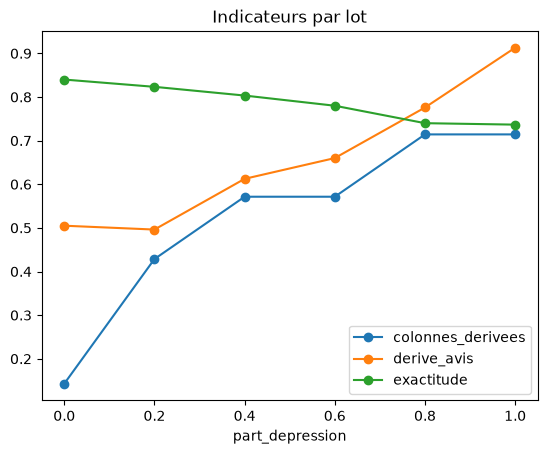

In [8]:
lignes = []
for part in [0, 0.2, 0.4, 0.6, 0.8, 1]:
  lot = fabrique_lot(part)
  instantane = rapport_derive.run(current_data=lot, reference_data=reference)
  metriques = instantane.dict()["metrics"]
  lignes.append(
    {
      "part_depression": part,
      "colonnes_derivees": metriques[0]["value"]["share"],
      "derive_avis": metriques[1]["value"],
      "alerte": leve_alerte(instantane),
      "exactitude": exactitude(lot.as_dataframe()),
    }
  )
tableau_de_bord = pandas.DataFrame(lignes)
tableau_de_bord.plot(
  x="part_depression",
  y=["colonnes_derivees", "derive_avis", "exactitude"],
  marker="o",
  title="Indicateurs par lot",
)
premier = tableau_de_bord.loc[tableau_de_bord["alerte"], "part_depression"].min()
print(f"Alerte levée dès {premier:.0%} d'avis Depression")
tableau_de_bord

Dès 20 % d'avis *Depression*, 43 % des colonnes surveillées dérivent : l'alerte est levée alors que l'exactitude n'a perdu que 2 points (84 % puis 82 %) : à analyser avant tout réentraînement. À 100 %, elle en a perdu 10. Les tests sur les entrées et les prédictions alertent tôt, sans attendre les étiquettes.

## 3. Dérive des concepts

Dans une dérive des concepts, les entrées ne changent pas : c'est leur lien avec la cible qui change, et les mêmes avis ne veulent plus dire la même chose. Simulons-la sur le lot de validation : les avis qui contiennent « work » (*works*, *worked*…) voient leur étiquette inversée, comme si le sens de ce mot s'était retourné pour les patients.

In [9]:
concept_df = actuel_df.copy()
inverses = concept_df["review"].str.contains("work", case=False)
concept_df.loc[inverses, "est_positif"] = 1 - concept_df.loc[inverses, "est_positif"]
concept = Dataset.from_pandas(
  concept_df, data_definition=definition_donnees, descriptors=descripteurs
)
instantane_derive = rapport_derive.run(current_data=concept, reference_data=reference)
print(f"Étiquettes inversées : {inverses.mean():.0%} des avis")
reponse = "oui" if leve_alerte(instantane_derive) else "non"
print(f"Alerte levée par les tests de dérive : {reponse}")

Étiquettes inversées : 40% des avis
Alerte levée par les tests de dérive : non


Les avis sont exactement ceux du lot de validation : aucun test de dérive ne peut voir le changement, et aucune alerte n'est levée.

### Rapport de qualité de classification

Une fois les étiquettes connues, Evidently compare la qualité des prédictions avant et après la dérive des concepts.

In [10]:
rapport = Report([ClassificationPreset()])
instantane = rapport.run(current_data=concept, reference_data=actuel)
instantane

L'exactitude tombe de 84 % à 55 % : seule la vérité terrain révèle une dérive des concepts. D'où la surveillance de la performance dès que les étiquettes arrivent, même tard.

## À retenir

- Dérive des données : visible sans étiquettes, dans les entrées et les prédictions (descripteurs, tests de dérive) ; elle trahit aussi les bugs de la chaîne de traitement.
- Dérive des concepts : invisible aux tests de dérive ; seule la performance mesurée sur la vérité terrain la révèle.
- Une alerte de dérive est un signal à analyser (bug ou vrai changement ?) avant de réentraîner.